# YOLOv8 for Danionella Fish Detection

Train and run inference with a custom YOLOv8 model for real-time fish tracking.  
Uses the Danionella dataset in `dc_freely-4/` or downloads it from Roboflow.

References: [Roboflow – Train YOLOv8 on Custom Data](https://blog.roboflow.com/how-to-train-yolov8-on-a-custom-dataset) · [Ultralytics](https://github.com/ultralytics/ultralytics)

In [1]:
import os

# Project root (run notebook from repo root so paths below resolve correctly)
HOME = os.getcwd()
print("Project root:", HOME)

Project root: <repo>\yolo


In [2]:
# Core imports for images and plotting
from PIL import Image
from matplotlib import pyplot as plt

In [3]:
from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.0.221 🚀 Python-3.8.13 torch-2.1.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1060 6GB, 6144MiB)
Setup complete ✅ (16 CPUs, 31.9 GB RAM, 175.9/232.3 GB disk)


In [4]:
from ultralytics import YOLO
from IPython.display import display, Image

In [5]:
import cv2

In [6]:
from tqdm.notebook import tqdm

In [7]:
from skimage.transform import rescale, resize, downscale_local_mean

# Training on the custom Danionella dataset

Either use the **bundled dataset** in `dc_freely-4/` or **download from Roboflow** (next cell).  
Set `ROBOFLOW_API_KEY` in your environment if you use Roboflow.

In [8]:
# Optional: download dataset from Roboflow. Skip this cell if you use the bundled dc_freely-4/.
from roboflow import Roboflow
_api_key = os.environ.get("ROBOFLOW_API_KEY", "")
if _api_key:
    rf = Roboflow(api_key=_api_key)
    project = rf.workspace("ljpdanionella-behaviour").project("dc_freely")
    dataset = project.version(4).download("yolov8")
else:
    dataset = None  # use local dc_freely-4/ instead


Extracting Dataset Version Zip to dc_freely-4 in yolov8:: 100%|████████████████████| 256/256 [00:00<00:00, 1581.88it/s]


In [9]:
# Path to dataset config: use Roboflow download location or bundled dc_freely-4/
try:
    data_path = os.path.join(dataset.location, "data.yaml") if dataset else None
except NameError:
    data_path = None
if not data_path or not os.path.exists(data_path or ""):
    data_path = os.path.join(HOME, "dataset", "data.yaml")
print("data.yaml path:", data_path)

data.yaml path: <repo>\yolo\dc_freely-4\data.yaml


In [10]:
# Load base YOLOv8 medium model (pretrained on COCO)
model = YOLO("yolov8m.pt")

100%|██████████████████████████████████████████████████████████████████████████████| 49.7M/49.7M [00:00<00:00, 110MB/s]


In [ ]:
# Train on Danionella data; imgsz=128 matches our preprocessing.
EPOCHS = 100  # final training procedure described in the thesis (Ch. 2.3)
results = model.train(data=data_path, epochs=EPOCHS, imgsz=128)

# Infer the model

## Inference: load image sequence

Load frames from a folder (e.g. `images_Roboflow/`) as a 3D array (H × W × N) for inference.

In [12]:
import numpy as np
import cv2
from ipywidgets import interact,IntSlider

In [13]:
# Folder of frames (relative to project root). Change if your images are elsewhere.
folder_path = os.path.join(HOME, "dataset", "test", "images")
image_files = sorted(
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
)

# Build stack (H x W x N) for batch inference
first_img = cv2.imread(os.path.join(folder_path, image_files[0]), cv2.IMREAD_GRAYSCALE)
h, w = first_img.shape
num_frames = len(image_files)
myVideo = np.zeros((h, w, num_frames), dtype=first_img.dtype)
for i, filename in enumerate(image_files):
    img = cv2.imread(os.path.join(folder_path, filename), cv2.IMREAD_GRAYSCALE)
    myVideo[:, :, i] = img
print(f"Loaded {num_frames} frames, shape {myVideo.shape}")


Loaded 54 frames, shape (251, 251, 54)


In [14]:
%matplotlib inline
def slider_movie(frame):
    plt.close()
    plt.figure(figsize=(5,2),dpi=150)
    plt.imshow(myVideo[:,:,frame],origin='lower')
    plt.show()
    
interact(slider_movie,frame=IntSlider(value=480,min=0,max=myVideo[:,:,:].shape[2]-1,step=10));

interactive(children=(IntSlider(value=53, description='frame', max=53, step=10), Output()), _dom_classes=('wid…

## Validate model on a single frame

Downscale frame to 128×128 (training resolution), run inference, and plot the bounding box.

In [17]:
from skimage.transform import downscale_local_mean
from PIL import Image
import numpy as np
from matplotlib.patches import Rectangle

frame = 30
img = myVideo[:, :, frame]
print(img.shape, img.dtype)

# Downscale
img = downscale_local_mean(img, (2, 2))
print(img.shape, img.dtype)

# Convert back to uint8 for display / PIL
img = np.clip(img, 0, 255).astype(np.uint8)

image = Image.fromarray(img)
#image.show()


(251, 251) uint8
(126, 126) float64


In [18]:
# Load trained weights (use your best run from runs/detect/trainN/weights/best.pt, or this checkpoint)
model = YOLO("yolo8m_live_tracking.pt")

In [19]:
# Run inference; conf=0.4 is the detection confidence threshold
results = model(image, show=False, conf=0.4)


0: 128x128 1 fish, 12.0ms
Speed: 2.0ms preprocess, 12.0ms inference, 3.0ms postprocess per image at shape (1, 3, 128, 128)


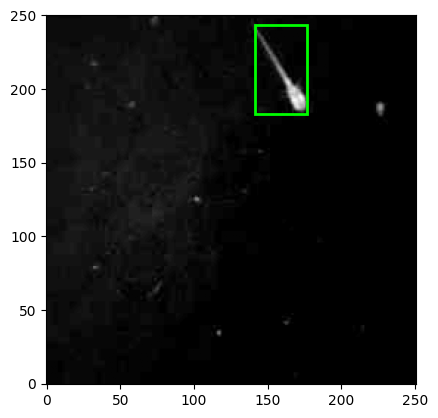

In [20]:
# Draw first detection box on the original (non-downscaled) frame
for result in results:
    boxes = result.boxes.cpu().numpy()
    xyxys = boxes.xyxy
    if len(xyxys) > 0:
        x1, y1, x2, y2 = xyxys[0]
        # Scale box back to original resolution (we downscaled by 2)
        x1, y1, x2, y2 = 2 * x1, 2 * y1, 2 * x2, 2 * y2
        fig, ax = plt.subplots()
        ax.imshow(myVideo[:, :, frame], origin="lower", cmap="gray")
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", linewidth=2))
        plt.show()
    break

## Run inference on full sequence

Run the model on every frame and store bounding boxes for inspection.

In [21]:
# Downscale factor (must match training); one box per frame
DOWNSCALE = 2
num_frames = myVideo.shape[2]
box = []
for idx in tqdm(range(num_frames), desc="inference", unit="frame"):
    img = downscale_local_mean(myVideo[:, :, idx].astype(np.float64), (DOWNSCALE, DOWNSCALE))
    img = np.clip(img, 0, 255).astype(np.uint8)
    results = model(Image.fromarray(img), show=False, conf=0.4)
    if not results or len(results[0].boxes) == 0:
        box.append(np.full(4, np.nan))
    else:
        xyxy = results[0].boxes.xyxy.cpu().numpy()
        box.append(xyxy[0])

inference:   0%|          | 0/54 [00:00<?, ?frame/s]


0: 128x128 1 fish, 13.0ms
Speed: 1.0ms preprocess, 13.0ms inference, 3.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128x128 1 fish, 14.0ms
Speed: 0.0ms preprocess, 14.0ms inference, 2.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128x128 1 fish, 12.0ms
Speed: 1.0ms preprocess, 12.0ms inference, 3.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128x128 1 fish, 13.0ms
Speed: 0.0ms preprocess, 13.0ms inference, 3.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128x128 1 fish, 12.0ms
Speed: 2.0ms preprocess, 12.0ms inference, 3.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128x128 1 fish, 12.0ms
Speed: 1.0ms preprocess, 12.0ms inference, 3.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128x128 1 fish, 14.0ms
Speed: 0.0ms preprocess, 14.0ms inference, 27.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128x128 1 fish, 12.0ms
Speed: 1.0ms preprocess, 12.0ms inference, 3.0ms postprocess per image at shape (1, 3, 128, 128)

0: 128

In [22]:
# Interactive slider: scrub through frames and overlay detection box (in downscaled coords)
%matplotlib inline
def slider_movie(frame):
    plt.close()
    fig, ax = plt.subplots()
    img = downscale_local_mean(myVideo[:, :, frame].astype(float), (2, 2))
    ax.imshow(img, origin="lower", cmap="gray")
    b = box[frame]
    if not np.isnan(b).any():
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="lime"))
interact(slider_movie, frame=IntSlider(value=0, min=0, max=myVideo.shape[2] - 1, step=1));

interactive(children=(IntSlider(value=0, description='frame', max=53), Output()), _dom_classes=('widget-intera…